we are going to build and visualise the Quantum Fourier Transform using Qiskit. The goal is to see how the QFT changes a computational basis state into a phase-based representation, and then verify the transformation by applying the inverse QFT(Quantum Fourier Transform).

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_state_city, plot_bloch_multivector
import numpy as np

In [3]:
n = 3

print(f"Number of qubits: {n}")

Number of qubits: 3


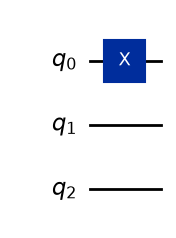

In [4]:
input_circuit = QuantumCircuit(n)

input_circuit.x(0)

input_circuit.draw("mpl")

In [5]:
initial_state = Statevector.from_instruction(input_circuit)

print(initial_state)

Statevector([0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j],
            dims=(2, 2, 2))


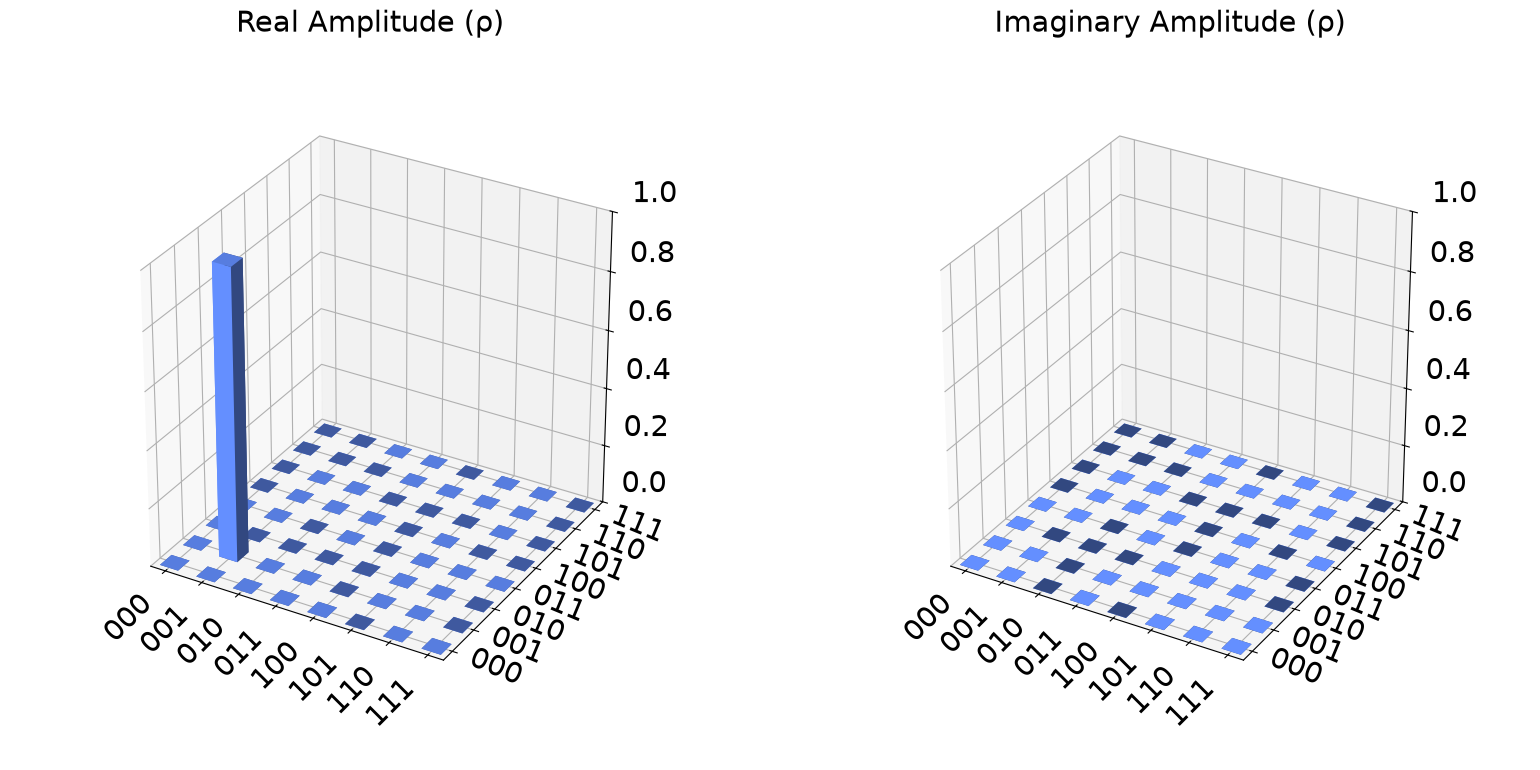

In [6]:
plot_state_city(initial_state)

In [7]:
def qft_circuit(n):
    qft = QuantumCircuit(n)

    for target in range(n):
        qft.h(target)

        for control in range(target + 1, n):
            angle = np.pi / (2 ** (control - target))
            qft.cp(angle, control, target)

    for qubit in range(n // 2):
        qft.swap(qubit, n - qubit - 1)

    return qft

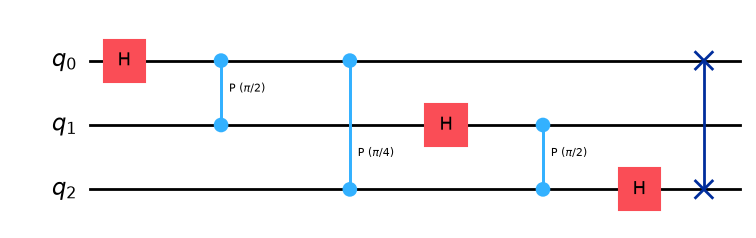

In [8]:
qft = qft_circuit(n)

qft.draw("mpl")

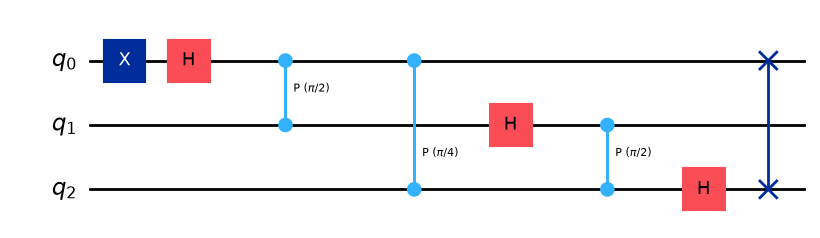

In [9]:
full_circuit = QuantumCircuit(n)

full_circuit.compose(input_circuit, inplace=True)
full_circuit.compose(qft, inplace=True)

full_circuit.draw("mpl")

In [10]:
qft_state = Statevector.from_instruction(full_circuit)

print(qft_state)

Statevector([ 0.35355339+0.j,  0.35355339+0.j,  0.35355339+0.j,
              0.35355339+0.j, -0.35355339+0.j, -0.35355339+0.j,
             -0.35355339+0.j, -0.35355339+0.j],
            dims=(2, 2, 2))


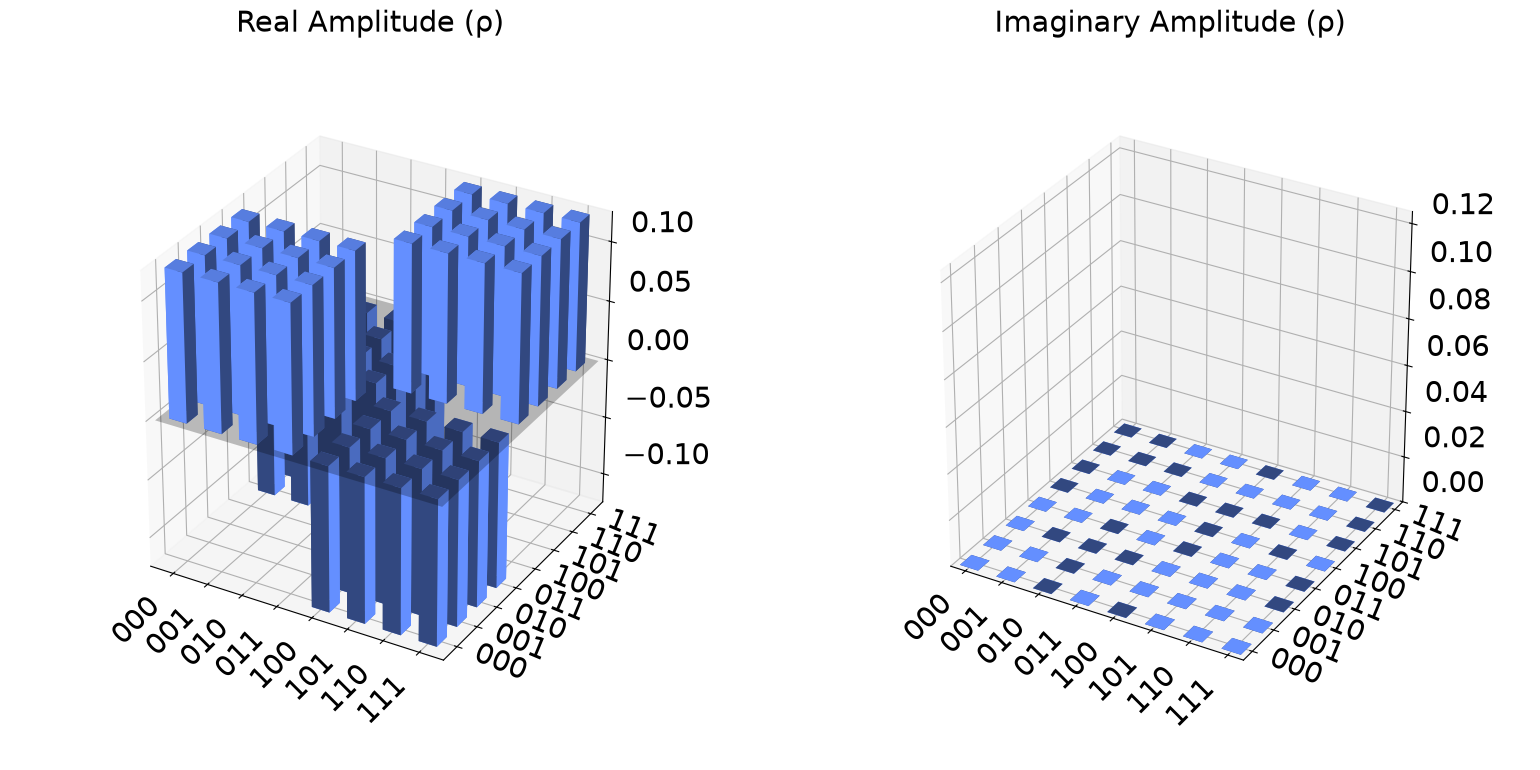

In [11]:
plot_state_city(qft_state)

In [12]:
probabilities = qft_state.probabilities_dict()

for state, probability in probabilities.items():
    print(f"{state}: {probability:.3f}")

000: 0.125
001: 0.125
010: 0.125
011: 0.125
100: 0.125
101: 0.125
110: 0.125
111: 0.125


In [13]:
for index, amplitude in enumerate(qft_state.data):
    phase = np.angle(amplitude)

    print(
        f"State |{index:03b}> "
        f"Amplitude = {amplitude:.3f}, "
        f"Phase = {phase:.3f} radians"
    )

State |000> Amplitude = 0.354+0.000j, Phase = 0.000 radians
State |001> Amplitude = 0.354+0.000j, Phase = 0.000 radians
State |010> Amplitude = 0.354+0.000j, Phase = 0.000 radians
State |011> Amplitude = 0.354+0.000j, Phase = 0.000 radians
State |100> Amplitude = -0.354+0.000j, Phase = 3.142 radians
State |101> Amplitude = -0.354+0.000j, Phase = 3.142 radians
State |110> Amplitude = -0.354+0.000j, Phase = 3.142 radians
State |111> Amplitude = -0.354+0.000j, Phase = 3.142 radians


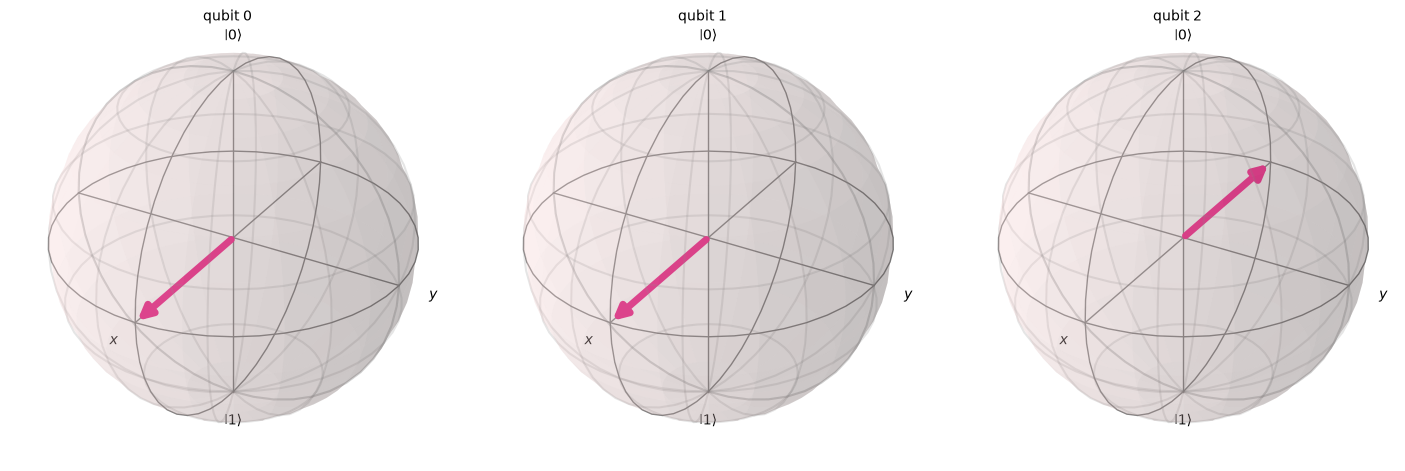

In [14]:
plot_bloch_multivector(qft_state)

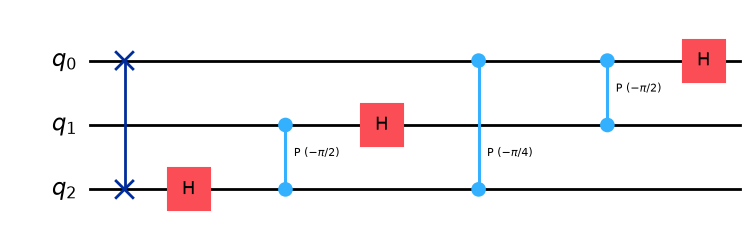

In [15]:
inverse_qft = qft.inverse()

inverse_qft.draw("mpl")

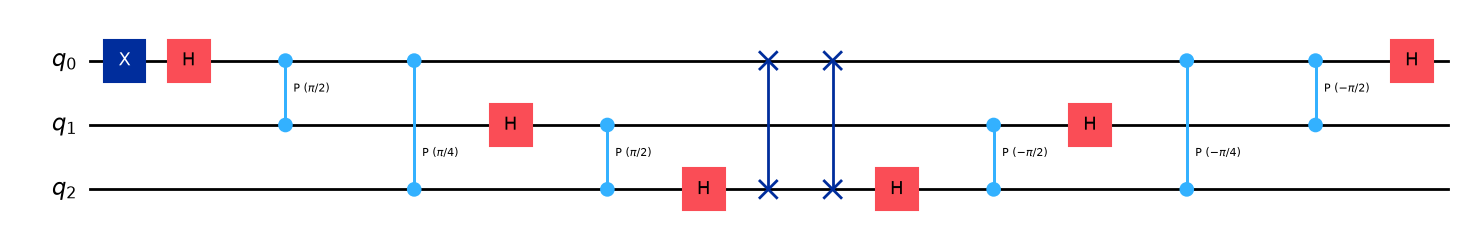

In [16]:
verification_circuit = QuantumCircuit(n)

verification_circuit.compose(input_circuit, inplace=True)
verification_circuit.compose(qft, inplace=True)
verification_circuit.compose(inverse_qft, inplace=True)

verification_circuit.draw("mpl")

In [17]:
recovered_state = Statevector.from_instruction(
    verification_circuit
)

print(recovered_state.probabilities_dict())

{np.str_('000'): np.float64(5.577060207443597e-34), np.str_('001'): np.float64(0.9999999999999991), np.str_('010'): np.float64(4.5355267350666824e-35), np.str_('011'): np.float64(4.5355267350666824e-35), np.str_('100'): np.float64(2.8358858847136396e-38), np.str_('101'): np.float64(1.6528754213149827e-37), np.str_('110'): np.float64(1.6528754213149827e-37), np.str_('111'): np.float64(2.8358858847136406e-38)}


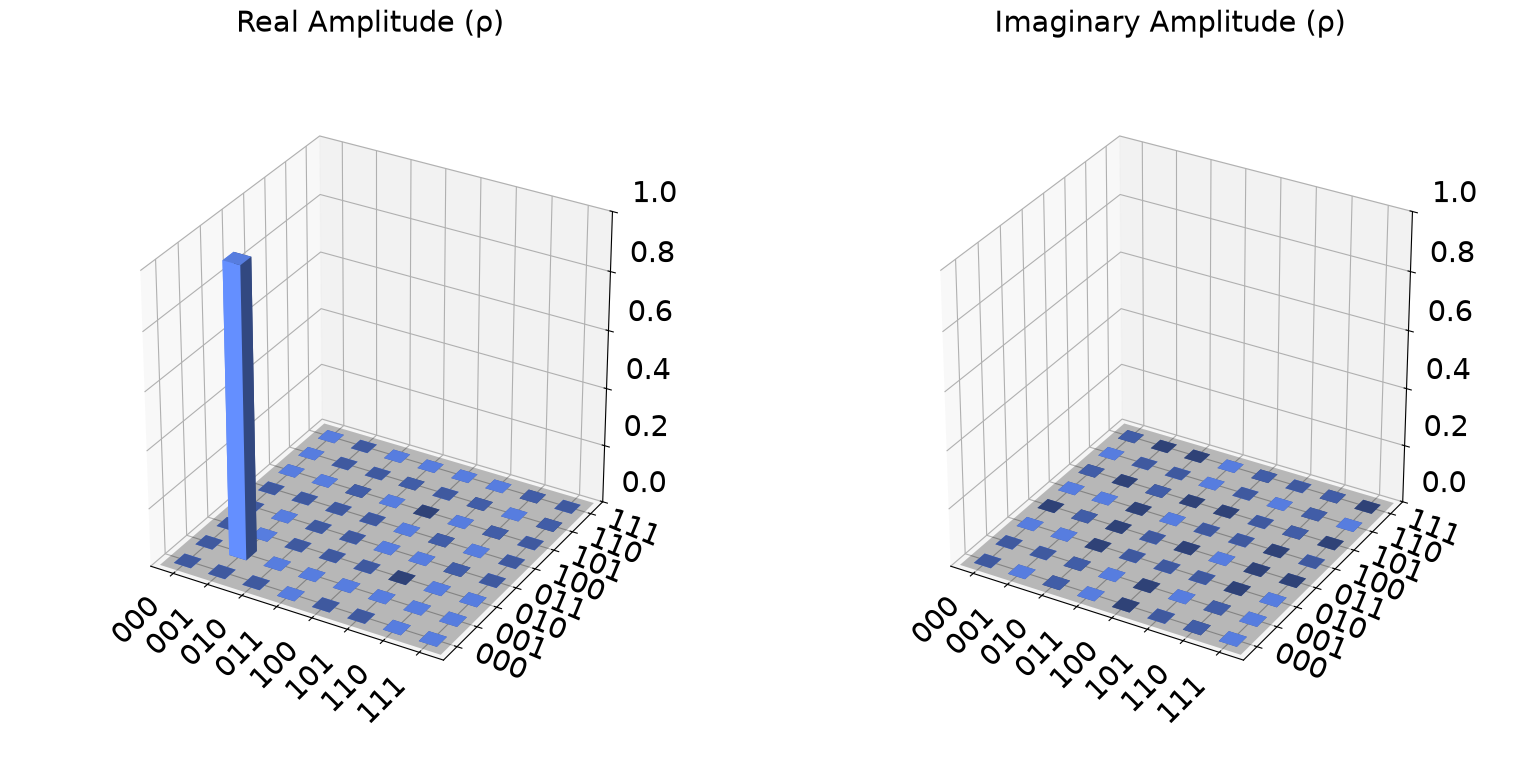

In [18]:
plot_state_city(recovered_state)